# Regresión Lasso: cómo se obtienen los estimadores

El ejercicio de las notas pide encontrar los estimadores lasso "tal como se realizó en el caso de la regresión ridge" e
investigar el algoritmo LARS. Con los datos normalizados como en (3.11), lasso minimiza

$$
S_\lambda(\boldsymbol\beta)=(\boldsymbol y-X\boldsymbol\beta)^T(\boldsymbol y-X\boldsymbol\beta)+\lambda\sum_{j=1}^p|\beta_j|,\qquad\lambda\ge0 .
$$ (eq-lasso)

(En las notas el índice de la suma aparece como $i=1$; la suma es sobre los coeficientes, $j=1,\dots,p$.)

**Por qué no sirve el camino de ridge.** En ridge derivamos e igualamos a cero, y la ecuación
$-2X^T\boldsymbol y+2X^TX\boldsymbol\beta+2\lambda\boldsymbol\beta=\mathbf 0$ se despeja. Aquí $|\beta_j|$ **no es derivable en
$\beta_j=0$**, que es justamente donde lasso deja muchos coeficientes. La herramienta adecuada es el subgradiente, y en
general no hay fórmula cerrada: hay una en el caso ortogonal y, en el caso general, algoritmos (descenso por
coordenadas y LARS).

## Condiciones de optimalidad

**Convexidad.** $\|\boldsymbol y-X\boldsymbol\beta\|^2$ es convexa (su hessiana $2X^TX$ es semidefinida positiva) y cada
$|\beta_j|$ es convexa, así que $S_\lambda$ es convexa. Además es continua y tiende a infinito cuando
$\|\boldsymbol\beta\|\to\infty$ si $\lambda>0$, así que tiene mínimo. Para una función convexa, $\hat{\boldsymbol\beta}$ es mínimo
global si y solo si $\mathbf 0$ pertenece a su subdiferencial en $\hat{\boldsymbol\beta}$.

**Subdiferencial del valor absoluto.** $\partial|b|=\{\operatorname{sign}(b)\}$ si $b\ne0$ y $\partial|b|=[-1,1]$ si $b=0$:
en el pico de $|b|$ cualquier pendiente entre $-1$ y $1$ deja la función por encima de la recta tangente.

````{prf:proposition} Condiciones KKT de lasso
:label: prop-kkt
Sea $\boldsymbol x_j$ la columna $j$ de $X$ y $\boldsymbol r=\boldsymbol y-X\hat{\boldsymbol\beta}$ el residuo. $\hat{\boldsymbol\beta}$ minimiza
{eq}`eq-lasso` si y solo si, para cada $j$,

$$
\boldsymbol x_j^T\boldsymbol r=\tfrac{\lambda}{2}\operatorname{sign}(\hat\beta_j)\ \ \text{si }\hat\beta_j\ne0,
\qquad |\boldsymbol x_j^T\boldsymbol r|\le\tfrac{\lambda}{2}\ \ \text{si }\hat\beta_j=0 .
$$
````

```{prf:proof}
El gradiente de la parte cuadrática es $-2X^T(\boldsymbol y-X\boldsymbol\beta)$, cuya componente $j$ es
$-2\boldsymbol x_j^T\boldsymbol r$. El subdiferencial de la penalización es el producto de los $\lambda\,\partial|\beta_j|$. Por
tanto, $\mathbf 0\in\partial S_\lambda(\hat{\boldsymbol\beta})$ equivale a que, para cada $j$, exista $g_j\in\partial|\hat\beta_j|$ con
$-2\boldsymbol x_j^T\boldsymbol r+\lambda g_j=0$, es decir, $\boldsymbol x_j^T\boldsymbol r=\tfrac\lambda2 g_j$. Si $\hat\beta_j\ne0$,
$g_j=\operatorname{sign}(\hat\beta_j)$; si $\hat\beta_j=0$, $g_j$ recorre $[-1,1]$, lo que da la desigualdad.
```

**Lectura.** Con datos estandarizados, $\boldsymbol x_j^T\boldsymbol r$ es proporcional a la correlación entre la predictora
$j$ y el residuo. Las variables activas tienen todas la misma correlación absoluta con el residuo, $\lambda/2$; una
variable queda fuera del modelo mientras su correlación con el residuo no alcance ese nivel. De aquí sale el umbral a
partir del cual el modelo queda vacío:

````{prf:corollary} Valor de $\lambda$ que anula todos los coeficientes
:label: cor-lmax
$\hat{\boldsymbol\beta}=\mathbf 0$ es solución si y solo si $\lambda\ge\lambda_{\max}:=2\max_j|\boldsymbol x_j^T\boldsymbol y|$.
````

```{prf:proof}
Con $\hat{\boldsymbol\beta}=\mathbf 0$ el residuo es $\boldsymbol y$, y todas las condiciones de la {prf:ref}`prop-kkt` son del
segundo tipo: $|\boldsymbol x_j^T\boldsymbol y|\le\lambda/2$ para todo $j$.
```

## Solución cerrada con predictoras ortogonales

````{prf:proposition} Umbral suave
:label: prop-umbral
Si las predictoras estandarizadas son ortogonales, $X^TX=nI_p$, y $b_j=\boldsymbol x_j^T\boldsymbol y/n$ es el estimador de
mínimos cuadrados, entonces

$$
\hat\beta_j^{\text{lasso}}=\operatorname{sign}(b_j)\Big(|b_j|-\frac{\lambda}{2n}\Big)_+ ,\qquad (u)_+=\max\{u,0\}.
$$ (eq-umbral)
````

```{prf:proof}
Desarrollando el cuadrado con $X^TX=nI$ y $X^T\boldsymbol y=n\boldsymbol b$:

$$
\begin{aligned}
S_\lambda(\boldsymbol\beta)&=\boldsymbol y^T\boldsymbol y-2n\,\boldsymbol b^T\boldsymbol\beta+n\,\boldsymbol\beta^T\boldsymbol\beta+\lambda\sum_j|\beta_j|\\
&=\boldsymbol y^T\boldsymbol y+\sum_{j=1}^p\big(n\beta_j^2-2nb_j\beta_j+\lambda|\beta_j|\big).
\end{aligned}
$$

La función se separa en $p$ problemas de una variable, $f(\beta)=n\beta^2-2nb\beta+\lambda|\beta|$, que minimizo por casos:

* Si $\beta>0$: $f'(\beta)=2n\beta-2nb+\lambda=0\Rightarrow\beta=b-\frac\lambda{2n}$, válido solo si $b>\frac\lambda{2n}$.
* Si $\beta<0$: $f'(\beta)=2n\beta-2nb-\lambda=0\Rightarrow\beta=b+\frac\lambda{2n}$, válido solo si $b<-\frac\lambda{2n}$.
* Si $|b|\le\frac\lambda{2n}$: ninguno de los dos casos es válido. Por la {prf:ref}`prop-kkt`, $\beta=0$ cumple
  $|-2nb+\lambda g|=0$ con $g=2nb/\lambda\in[-1,1]$, así que el mínimo está en $0$.

Los tres casos se resumen en {eq}`eq-umbral`.
```

**Comparación con ridge.** En el mismo caso ortogonal, ridge da $\hat\beta_j^{\text{ridge}}=b_j/(1+\lambda/n)$: multiplica
por un factor menor que uno, así que **contrae pero nunca anula**. Lasso **resta** $\lambda/(2n)$ al valor absoluto y
trunca en cero: por eso produce coeficientes exactamente iguales a cero, que es la afirmación de las notas.

## Caso general: descenso por coordenadas

Sin ortogonalidad no hay fórmula cerrada, pero la {prf:ref}`prop-umbral` resuelve el problema **en una sola coordenada**
con las demás fijas. Si $\boldsymbol r^{(j)}=\boldsymbol y-\sum_{k\ne j}\boldsymbol x_k\beta_k$ es el residuo parcial, la función en
$\beta_j$ es $\|\boldsymbol r^{(j)}-\boldsymbol x_j\beta_j\|^2+\lambda|\beta_j|$ más una constante, y su mínimo es

$$
\beta_j\leftarrow\frac{\operatorname{sign}(\boldsymbol x_j^T\boldsymbol r^{(j)})\big(|\boldsymbol x_j^T\boldsymbol r^{(j)}|-\lambda/2\big)_+}{\boldsymbol x_j^T\boldsymbol x_j}.
$$ (eq-cd)

Repetir {eq}`eq-cd` para $j=1,\dots,p$ hasta que nada cambie es el **descenso por coordenadas**. Cada paso no aumenta
$S_\lambda$, y como la parte no derivable es separable por coordenadas, el método converge al mínimo global (Tseng,
2001). Es el algoritmo que usa `sklearn.linear_model.Lasso`.

## El algoritmo LARS

Efron, Hastie, Johnstone y Tibshirani (2004) propusieron *Least Angle Regression*. En vez de resolver para un
$\lambda$ fijo, LARS construye **todo el camino** de soluciones al variar $\lambda$ desde $\lambda_{\max}$ hasta $0$:

1. Empieza con $\boldsymbol\beta=\mathbf 0$ y $\boldsymbol r=\boldsymbol y$. Activa la predictora más correlacionada con el residuo
   (la que da $\lambda_{\max}$ en el {prf:ref}`cor-lmax`).
2. Mueve los coeficientes activos en la **dirección equiangular**: la que mantiene iguales las correlaciones absolutas
   de todas las activas con el residuo, que van bajando juntas.
3. Avanza hasta que una predictora inactiva alcanza esa misma correlación; la activa y repite.
4. **Modificación lasso:** si un coeficiente activo llega a cero, lo saca del conjunto activo y recalcula la
   dirección.

Con la modificación del paso 4, LARS da exactamente el camino de lasso. La razón es que el camino es **lineal a
trozos**:

````{prf:proposition} El camino de lasso es lineal a trozos
:label: prop-camino
En un intervalo de $\lambda$ en el que el conjunto activo $\mathcal A$ y los signos $\boldsymbol s=\operatorname{sign}(\hat{\boldsymbol\beta}_{\mathcal A})$
no cambian, y $X_{\mathcal A}^TX_{\mathcal A}$ es invertible,

$$
\hat{\boldsymbol\beta}_{\mathcal A}(\lambda)=(X_{\mathcal A}^TX_{\mathcal A})^{-1}\Big(X_{\mathcal A}^T\boldsymbol y-\frac{\lambda}{2}\boldsymbol s\Big),
$$

que es una función afín de $\lambda$.
````

```{prf:proof}
Para las activas, la {prf:ref}`prop-kkt` dice $X_{\mathcal A}^T(\boldsymbol y-X_{\mathcal A}\hat{\boldsymbol\beta}_{\mathcal A})=\frac\lambda2\boldsymbol s$
(las inactivas valen cero y no aportan al residuo). Despejando se obtiene la fórmula.
```

Así, el camino completo queda determinado por los valores de $\lambda$ en los que una variable entra o sale. LARS
calcula esos quiebres uno por uno, con un costo del orden de un ajuste por mínimos cuadrados.

## Verificación numérica

Uso los datos `diabetes` de scikit-learn ($n=442$, $p=10$), estandarizados como en (3.11). La equivalencia de escalas
es la siguiente: scikit-learn minimiza $\frac1{2n}\|\boldsymbol y-X\boldsymbol w\|^2+\alpha\|\boldsymbol w\|_1$. Multiplicar
{eq}`eq-lasso` por $\frac1{2n}$ no cambia el minimizador, así que $\alpha=\lambda/(2n)$.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_diabetes
from sklearn.linear_model import Lasso, lars_path

X0, y0 = load_diabetes(return_X_y=True)
X = (X0 - X0.mean(0)) / X0.std(0)          # (3.11): columnas con media 0 y suma de cuadrados n
y = y0 - y0.mean()
n, p = X.shape
nombres = load_diabetes().feature_names


def umbral_suave(u, t):
    return np.sign(u) * np.maximum(np.abs(u) - t, 0.0)


def lasso_coordenadas(X, y, lam, tol=1e-12, max_iter=10_000):
    """Descenso por coordenadas para (y - Xb)^T (y - Xb) + lam * sum|b_j|, ecuación (eq-cd)."""
    b = np.zeros(X.shape[1])
    r = y.copy()
    normas = (X ** 2).sum(0)
    for _ in range(max_iter):
        cambio = 0.0
        for j in range(X.shape[1]):
            r += X[:, j] * b[j]                       # residuo parcial r^(j)
            nuevo = umbral_suave(X[:, j] @ r, lam / 2) / normas[j]
            r -= X[:, j] * nuevo
            cambio = max(cambio, abs(nuevo - b[j]))
            b[j] = nuevo
        if cambio < tol:
            break
    return b


lam_max = 2 * np.abs(X.T @ y).max()
filas = []
for frac in [0.5, 0.1, 0.01]:
    lam = frac * lam_max
    propio = lasso_coordenadas(X, y, lam)
    sk = Lasso(alpha=lam / (2 * n), fit_intercept=False, tol=1e-12, max_iter=100_000).fit(X, y).coef_
    r = y - X @ propio
    kkt = X.T @ r
    activos = propio != 0
    filas.append({
        "lambda / lambda_max": frac,
        "coeficientes distintos de 0": int(activos.sum()),
        "max |propio - sklearn|": np.abs(propio - sk).max(),
        "max | x_j^T r | en activas - lambda/2": np.abs(np.abs(kkt[activos]) - lam / 2).max() if activos.any() else 0,
        "max |x_j^T r| en inactivas / (lambda/2)": (np.abs(kkt[~activos]).max() / (lam / 2)) if (~activos).any() else np.nan,
    })
pd.DataFrame(filas).round(8)

,lambda / lambda_max,coeficientes distintos de 0,max |propio - sklearn|,max | x_j^T r | en activas - lambda/2,max |x_j^T r| en inactivas / (lambda/2)
0,0.50,2,0.0,0.0,0.979108
1,0.10,5,0.0,0.0,0.972303
2,0.01,8,0.0,0.0,0.471512


El descenso por coordenadas escrito desde cero coincide con scikit-learn (diferencias del orden de $10^{-8}$ o menos) y
las condiciones KKT se cumplen: en las variables activas $|\boldsymbol x_j^T\boldsymbol r|=\lambda/2$, y en las inactivas el
cociente es menor o igual que $1$. Con $\lambda$ grande quedan pocas variables distintas de cero.

Ahora compruebo el {prf:ref}`cor-lmax` y el camino de LARS. `lars_path` devuelve los valores de $\alpha$ en los quiebres
y los coeficientes en cada uno; los comparo con lasso resuelto en esos mismos $\alpha$:

lambda_max = 39921.47
coeficientes con lambda = 1.0001 * lambda_max: 0
coeficientes con lambda = 0.9999 * lambda_max: 1


quiebres del camino: 13 | max diferencia LARS vs descenso por coordenadas: 5.56e-11
orden de entrada de las variables: ['bmi', 's5', 'bp', 'sex', 's6', 's1', 's4', 's2', 'age', 's3']


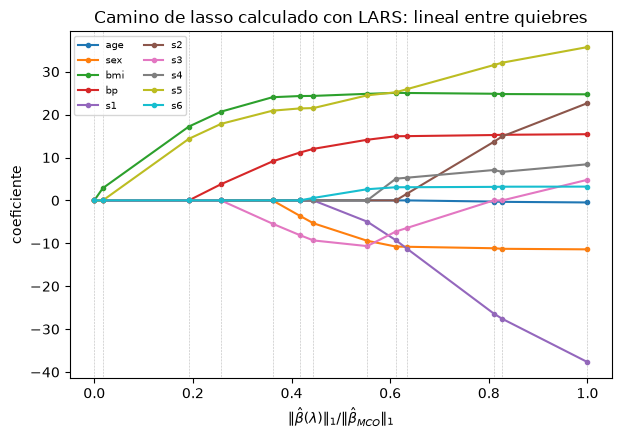

In [2]:
print(f"lambda_max = {lam_max:.2f}")
print("coeficientes con lambda = 1.0001 * lambda_max:", np.count_nonzero(lasso_coordenadas(X, y, 1.0001 * lam_max)))
print("coeficientes con lambda = 0.9999 * lambda_max:", np.count_nonzero(lasso_coordenadas(X, y, 0.9999 * lam_max)))

alphas, activos, coefs = lars_path(X, y, method="lasso")
dif = [np.abs(coefs[:, k] - lasso_coordenadas(X, y, 2 * n * a)).max() for k, a in enumerate(alphas) if a > 0]
print(f"quiebres del camino: {len(alphas)} | max diferencia LARS vs descenso por coordenadas: {max(dif):.2e}")
print("orden de entrada de las variables:", [nombres[j] for j in activos])

fig, ax = plt.subplots(figsize=(7, 4.5))
t = np.abs(coefs).sum(0) / np.abs(coefs[:, -1]).sum()
for j in range(p):
    ax.plot(t, coefs[j], marker=".", label=nombres[j])
for x in t:
    ax.axvline(x, color="gray", lw=0.4, ls=":")
ax.set(xlabel=r"$\|\hat\beta(\lambda)\|_1 / \|\hat\beta_{MCO}\|_1$", ylabel="coeficiente",
       title="Camino de lasso calculado con LARS: lineal entre quiebres")
ax.legend(fontsize=7, ncol=2)
plt.show()

El camino es lineal entre los quiebres (líneas punteadas) y en el extremo derecho, con $\lambda=0$, llega a la
solución de mínimos cuadrados. Por último compruebo la fórmula cerrada {eq}`eq-umbral` con una matriz de predictoras
ortogonales construida a propósito:

In [3]:
rng = np.random.default_rng(1)
Q, _ = np.linalg.qr(rng.normal(size=(100, 5)) - 0)
Q -= Q.mean(0)
Q, _ = np.linalg.qr(Q)                       # columnas ortonormales y centradas
Xo = Q * np.sqrt(100)                        # X^T X = n I
yo = Xo @ np.array([3.0, -2.0, 0.5, 0.0, 1.0]) + rng.normal(size=100)
yo -= yo.mean()
b = Xo.T @ yo / 100
lam = 150.0
cerrada = umbral_suave(b, lam / (2 * 100))
numerica = lasso_coordenadas(Xo, yo, lam)
pd.DataFrame({"MCO b_j": b, "lasso fórmula (umbral suave)": cerrada, "lasso numérico": numerica,
              "ridge b_j/(1+lambda/n)": b / (1 + lam / 100)}).round(5)

,MCO b_j,lasso fórmula (umbral suave),lasso numérico,ridge b_j/(1+lambda/n)
0,3.09209,2.34209,2.34209,1.23684
1,-2.02097,-1.27097,-1.27097,-0.80839
2,0.34548,0.00000,0.00000,0.13819
3,-0.04147,-0.00000,-0.00000,-0.01659
4,1.15927,0.40927,0.40927,0.46371


La fórmula de umbral suave reproduce la solución numérica. Con el mismo $\lambda$, lasso lleva a cero los coeficientes
pequeños, mientras que ridge solo los contrae.

**Referencias.** Efron, B., Hastie, T., Johnstone, I. y Tibshirani, R. (2004). Least angle regression. *The Annals of
Statistics*, 32(2), 407–499. · Tibshirani, R. (1996). Regression shrinkage and selection via the lasso. *Journal of the
Royal Statistical Society B*, 58(1), 267–288. · Tseng, P. (2001). Convergence of a block coordinate descent method for
nondifferentiable minimization. *Journal of Optimization Theory and Applications*, 109(3), 475–494.